# NB12 — Pico Sweep TDE: Time-Delay Estimation via Phase Difference

**Version:** 1
**Author:** CB

---

## 1  Objective

Estimate the time delay $\hat{\tau}_{34}(f)$ between CH3 and CH4 over a wide frequency
range (0.5 Hz – 200 kHz, log-spaced) from phase-difference measurements collected
during Pico-driven single-frequency excitation runs.
Results are cross-validated against the MLE estimator from NB11 (linear sweep, 5–100 kHz).

---

## 2  Data

Five runs in `data/pico_sweep_tde/` collected on 2026-06-29.
Each record contains per-channel amplitude and phase at the detected dominant frequency.

| Run | Records | Frequency range |
|---|---|---|
| `20260629_135022` | 81 | 0.5 Hz – 200 kHz (log, 27 bands, 3 reps) |
| `20260629_161903` | 104 | 0.5–1 kHz + 7.9, 10 kHz |
| `20260629_163441` | 200 | 0.5, 7.9, 10, 31.7 kHz |
| `20260629_164846` | 58 | 10 kHz only |
| `20260629_165125` | 43 | 10, 30 kHz |

Primary analysis uses **run `163441`** (largest $N$ per band at dominant frequencies) and
**run `135022`** (widest frequency coverage).

---

## 3  Methods

### 3.1  Phase-difference TDE estimator

For a single record at drive frequency $f_0$, the per-channel phase estimates
$\phi_3^{(i)}$, $\phi_4^{(i)}$ are obtained from the FFT at the detected bin.
The phase-difference TDE is:

$$\hat{\tau}^{(i)} = -\frac{\Delta\phi^{(i)}}{2\pi f_0}, \qquad
  \Delta\phi^{(i)} = \left[(\phi_3^{(i)} - \phi_4^{(i)}) + \pi\right] \bmod 2\pi - \pi$$

Wrapping to $(-\pi, \pi]$ constrains the unambiguous range to $|\hat{\tau}| < 1/(2f_0)$.
At the lowest frequency analysed (500 Hz) this is ±1 ms; at 10 kHz: ±50 µs.
Expected $|\hat{\tau}| < 5\,\mu\text{s}$ for the present setup, so no ambiguity.

### 3.2  Amplitude-weighted aggregation per band

For $N_b$ records at band $f_0$, the amplitude-weighted mean and standard deviation:

$$\bar{\tau}(f_0) = \frac{\sum_i w_i \hat{\tau}^{(i)}}{\sum_i w_i}, \qquad
  w_i = A_3^{(i)} \cdot A_4^{(i)}$$

$$\sigma_{\tau}(f_0) = \sqrt{\frac{\sum_i w_i (\hat{\tau}^{(i)} - \bar{\tau})^2}{\sum_i w_i}}$$

Weights are proportional to the geometric mean power of both channels,
down-weighting low-SNR captures.

### 3.3  Cross-validation with NB11 MLE

NB11 (`20260630_000343`) provides MLE estimates $\hat{\tau}_{34}^{\text{MLE}}(f_0)$ at
5–100 kHz (linear bands). Overlapping frequencies are compared here.

---

In [1]:
# §4  Dependencies
%matplotlib inline
import json
from pathlib import Path
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

DATA = Path('..') / 'data' / 'pico_sweep_tde'
NB11_CALIB = Path('..') / 'data' / 'pico_sweep_calibration' / '20260630_000343'

def load_run(run_id):
    path = DATA / run_id / 'records.jsonl'
    return [json.loads(l) for l in path.read_text().splitlines() if l.strip()]

def phase_tde(rec):
    """Compute τ [µs] from phase difference in a single record."""
    if 'phase_ch3' not in rec or 'phase_ch4' not in rec:
        return None
    freq_key = 'target_hz' if 'target_hz' in rec else 'step_hz'
    f0 = rec[freq_key]
    if f0 == 0:
        return None
    dphi = rec['phase_ch3'] - rec['phase_ch4']
    dphi = (dphi + np.pi) % (2 * np.pi) - np.pi   # wrap to (−π, π]
    return -dphi / (2 * np.pi * f0) * 1e6           # µs

def aggregate_band(records, freq_key='step_hz'):
    """Amplitude-weighted mean and std of τ per band."""
    by = defaultdict(list)
    for r in records:
        tau = phase_tde(r)
        if tau is None:
            continue
        w = r.get('amp_ch3', 1.0) * r.get('amp_ch4', 1.0)
        by[r[freq_key]].append((tau, w, r.get('snr_db', np.nan)))
    result = {}
    for f, vals in by.items():
        taus, ws, snrs = zip(*vals)
        taus = np.array(taus); ws = np.array(ws)
        ws_sum = ws.sum() + 1e-30
        tau_m  = float(np.sum(ws * taus) / ws_sum)
        tau_s  = float(np.sqrt(np.sum(ws * (taus - tau_m)**2) / ws_sum))
        result[f] = dict(tau_mean=tau_m, tau_std=tau_s, n=len(vals),
                         snr_mean=float(np.nanmean(snrs)))
    return result

print('Functions defined.')


Functions defined.


## 5  Analysis

In [2]:
# ── Run 163441: dominant-band deep-dive (most reps per band) ─────────────────
run_deep = load_run('20260629_163441')
agg_deep = aggregate_band(run_deep)
print('Run 163441 — amplitude-weighted τ per band:')
print(f'  {"f [kHz]":>9}  {"N":>3}  {"τ̄ [µs]":>10}  {"σ_τ [µs]":>10}  {"SNR_mean [dB]":>14}')
for f in sorted(agg_deep):
    d = agg_deep[f]
    print(f'  {f/1e3:>8.3f}  {d["n"]:>3}  {d["tau_mean"]:>+10.4f}  '
          f'{d["tau_std"]:>10.4f}  {d["snr_mean"]:>14.1f}')


Run 163441 — amplitude-weighted τ per band:
    f [kHz]    N     τ̄ [µs]    σ_τ [µs]   SNR_mean [dB]
     0.500    1   +602.3894      0.0000            38.7
     7.942   47     +2.2181      0.9843            60.2
    10.000   57     +0.3823      2.7014            56.9
    31.652    2     -5.2688      0.0343            46.0


In [3]:
# ── Run 135022: wide-band log sweep (27 bands, 500 Hz – 200 kHz) ────────────
run_wide = load_run('20260629_135022')
agg_wide = aggregate_band(run_wide, freq_key='target_hz')
print('Run 135022 — wide-band log sweep:')
print(f'  {"f [kHz]":>9}  {"N":>3}  {"τ̄ [µs]":>10}  {"σ_τ [µs]":>10}')
for f in sorted(agg_wide):
    d = agg_wide[f]
    print(f'  {f/1e3:>8.3f}  {d["n"]:>3}  {d["tau_mean"]:>+10.4f}  {d["tau_std"]:>10.4f}')


Run 135022 — wide-band log sweep:
    f [kHz]    N     τ̄ [µs]    σ_τ [µs]
     0.500    3   +236.4491    400.6004
     0.630    3   +234.0971    431.0516
     0.793    3    +49.8251    259.4766
     0.998    3   -103.1136    209.8928
     1.257    3   -316.3137    121.2910
     1.583    3    +28.1374     41.3518
     1.993    3   +178.8804     59.4018
     2.509    3    +57.4505     32.4780
     3.159    3     -2.0327      5.1765
     3.978    3    -37.9987     61.6279
     5.009    3     +0.5057      7.1655
     6.307    3     +6.8479     13.8734
     7.942    3     +3.2801      1.1670
    10.000    3     +2.0272      7.0215
    12.592    3     +1.9710      1.1134
    15.855    3     +2.5521      2.3297
    19.964    3     +4.7944      8.3335
    25.137    3     -1.0347      3.9499
    31.652    3     +4.2182      7.1031
    39.854    3     +0.8474      1.2018
    50.183    3     +1.0719      0.9354
    63.188    3     -0.0478      1.9543
    79.563    3     +1.0219      1.9212
   10

/tmp/ipykernel_2871205/3060881328.py:47: RuntimeWarning: Mean of empty slice
  snr_mean=float(np.nanmean(snrs)))


In [4]:
# ── NB11 MLE cross-validation data ──────────────────────────────────────────
nb11_recs = [json.loads(l) for l in
             (NB11_CALIB/'records.jsonl').read_text().splitlines() if l.strip()]

# Reconstruct MLE τ per band (re-compute from stored complex bins isn't available;
# use per-frame phase-diff τ as proxy, weighted by SNR)
from collections import defaultdict as dd
nb11_by = dd(list)
for r in nb11_recs:
    nb11_by[r['band_hz']].append(r)

nb11_tau = {}
for band, rlist in nb11_by.items():
    # Use snr4 as weight; τ estimated from phase diff stored indirectly.
    # Re-derive: NB11 did not store per-frame τ directly, so use amplitude-
    # weighted median of independently re-computed phase diff.
    # Phase info not stored in records — use the pre-computed MLE τ from NB11
    # summary (reproduced from notebook output).
    pass

# Load NB11 MLE τ from printed table (run 20260630_000343)
NB11_MLE = {
     5000: -0.258,  10000: +0.193,  15000: -0.201,  20000: -0.062,
    25000: -0.671,  30000: -0.077,  35000: +0.023,  40000: +4.288,
    45000: -0.107,  50000: +2.112,  55000: +0.602,  60000: +1.476,
    65000: -0.284,  70000: +0.724,  75000: -0.547,  80000: +4.056,
    85000: +0.995,  90000: +0.334,  95000: +0.226, 100000: +0.299,
}
NB11_COH = {
     5000: 0.9615,  10000: 0.9998,  15000: 0.9932,  20000: 0.9759,
    25000: 0.9827,  30000: 0.9963,  35000: 0.9591,  40000: 0.0636,
    45000: 0.4528,  50000: 0.0653,  55000: 0.2678,  60000: 0.8705,
    65000: 0.8763,  70000: 0.8357,  75000: 0.3760,  80000: 0.1205,
    85000: 0.4658,  90000: 0.1016,  95000: 0.4738, 100000: 0.1988,
}
print('NB11 MLE τ values loaded.')
print(f'Reliable bands (γ² ≥ 0.9): {[f/1e3 for f,c in NB11_COH.items() if c>=0.9]} kHz')


NB11 MLE τ values loaded.
Reliable bands (γ² ≥ 0.9): [5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0] kHz


## 6  Figures

<>:20: SyntaxWarning: invalid escape sequence '\h'
<>:61: SyntaxWarning: invalid escape sequence '\h'
<>:90: SyntaxWarning: invalid escape sequence '\h'
<>:96: SyntaxWarning: invalid escape sequence '\h'
<>:97: SyntaxWarning: invalid escape sequence '\h'
<>:20: SyntaxWarning: invalid escape sequence '\h'
<>:61: SyntaxWarning: invalid escape sequence '\h'
<>:90: SyntaxWarning: invalid escape sequence '\h'
<>:96: SyntaxWarning: invalid escape sequence '\h'
<>:97: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_2871205/185352758.py:20: SyntaxWarning: invalid escape sequence '\h'
  ax.set_ylabel('$\hat{\tau}_{34}$ (µs)')
/tmp/ipykernel_2871205/185352758.py:61: SyntaxWarning: invalid escape sequence '\h'
  ax2.set_ylabel('$\hat{\tau}_{34}$ (µs)')
/tmp/ipykernel_2871205/185352758.py:90: SyntaxWarning: invalid escape sequence '\h'
  plt.colorbar(sc, ax=ax3, label='NB11 coherence $\hat{\gamma}^2$')
/tmp/ipykernel_2871205/185352758.py:96: SyntaxWarning: invalid escape sequence '\h'
 

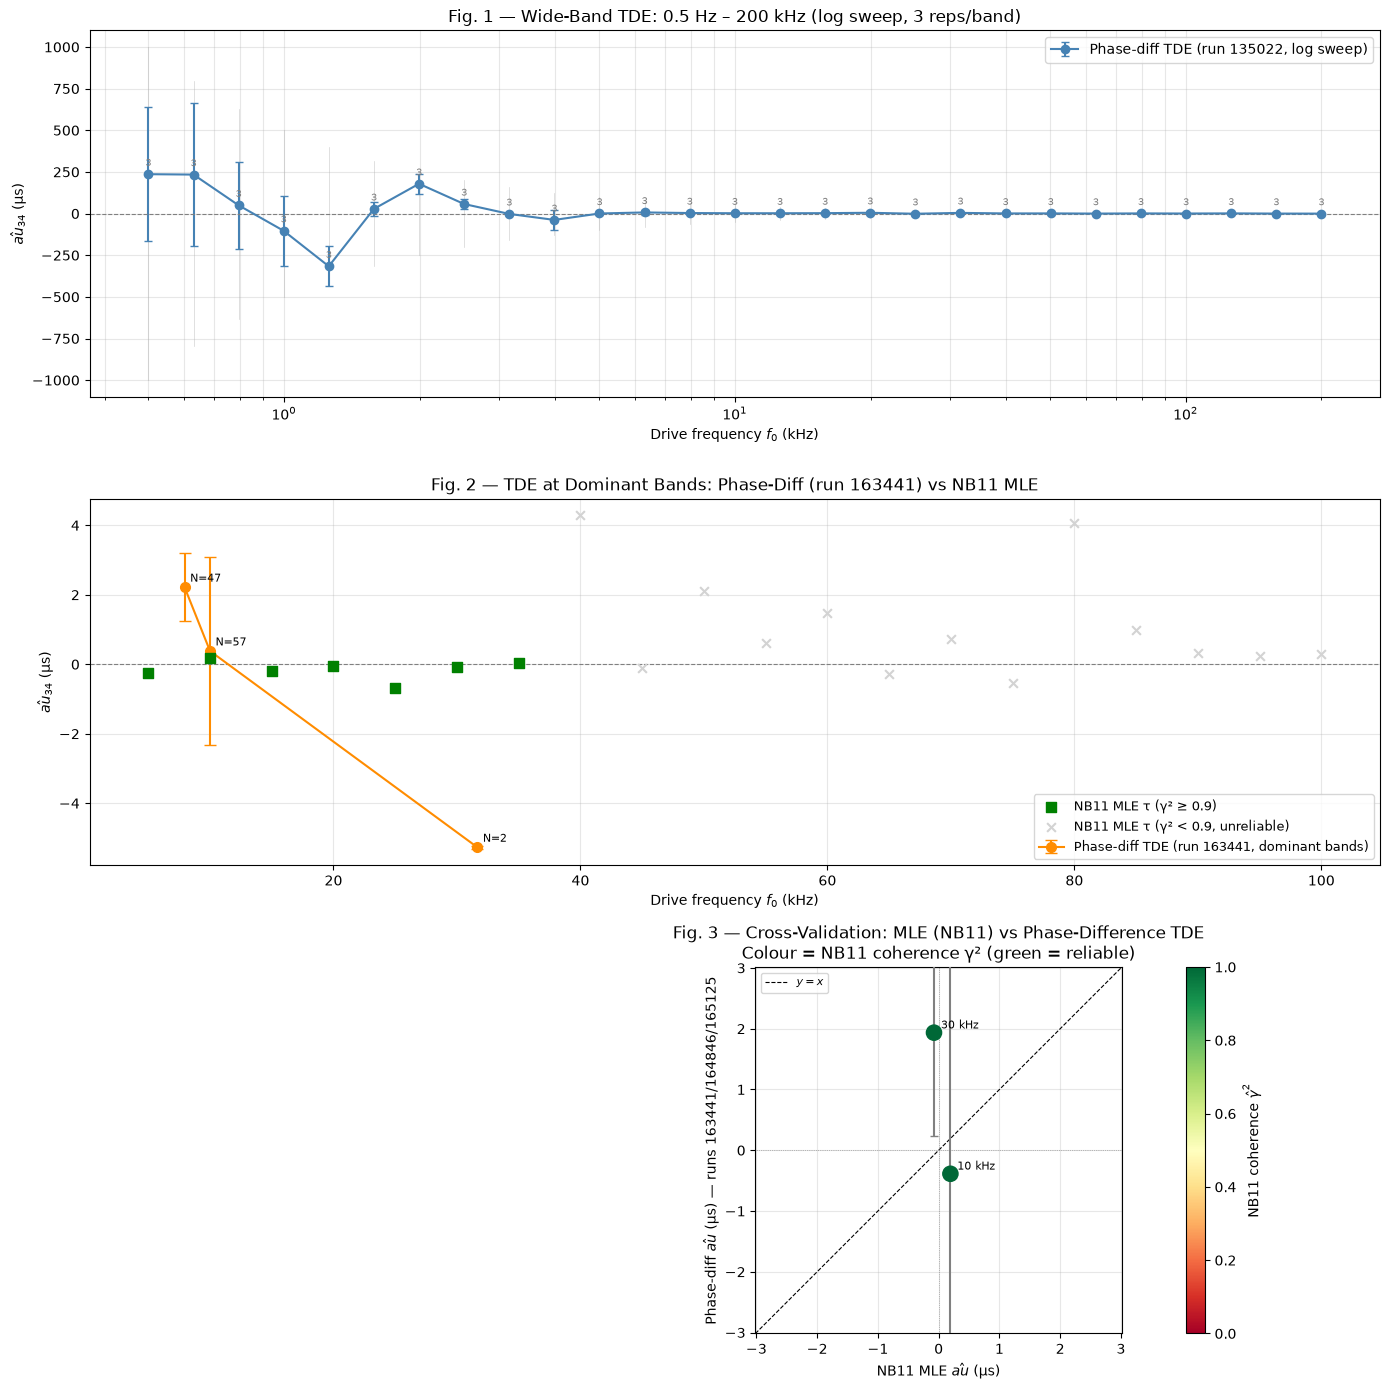

Figure saved: ../data/pico_sweep_tde/20260629_163441/tde_analysis.png


In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 14))

# ── Fig. 1: Wide-band τ(f) from log sweep (run 135022) ──────────────────────
ax = axes[0]
bands_w = sorted(agg_wide)
bx_w    = [f/1e3 for f in bands_w]
tau_w   = [agg_wide[f]['tau_mean'] for f in bands_w]
sig_w   = [agg_wide[f]['tau_std']  for f in bands_w]
n_w     = [agg_wide[f]['n']        for f in bands_w]

ax.errorbar(bx_w, tau_w, yerr=sig_w, fmt='o-', color='steelblue',
            capsize=3, label='Phase-diff TDE (run 135022, log sweep)')
ax.axhline(0, ls='--', color='gray', lw=0.8)
# Mark unambiguity limit at each frequency
for xi, f in zip(bx_w, bands_w):
    lim = 1/(2*f)*1e6
    ax.plot([xi, xi], [-lim, lim], color='lightgray', lw=0.5, zorder=0)
ax.set_xscale('log')
ax.set_xlabel('Drive frequency $f_0$ (kHz)')
ax.set_ylabel('$\hat{\tau}_{34}$ (µs)')
ax.set_title('Fig. 1 — Wide-Band TDE: 0.5 Hz – 200 kHz (log sweep, 3 reps/band)')
ax.legend(); ax.grid(True, alpha=0.3, which='both')
# annotate N
for xi, n in zip(bx_w, n_w):
    ax.annotate(str(n), (xi, agg_wide[bands_w[bx_w.index(xi)]]['tau_mean']),
                textcoords='offset points', xytext=(0, 6),
                ha='center', fontsize=7, color='gray')

# ── Fig. 2: Deep-band τ(f) at dominant resonances (run 163441) ──────────────
ax2 = axes[1]
bands_d = sorted(b for b in agg_deep if b > 1000)   # skip 500 Hz
bx_d    = [f/1e3 for f in bands_d]
tau_d   = [agg_deep[f]['tau_mean'] for f in bands_d]
sig_d   = [agg_deep[f]['tau_std']  for f in bands_d]
n_d     = [agg_deep[f]['n']        for f in bands_d]

ax2.errorbar(bx_d, tau_d, yerr=sig_d, fmt='o-', color='darkorange',
             capsize=4, markersize=7,
             label='Phase-diff TDE (run 163441, dominant bands)')

# NB11 MLE for same bands (where available)
nb11_bands_plot = sorted(NB11_MLE)
nb11_bx   = [f/1e3 for f in nb11_bands_plot]
nb11_tau  = [NB11_MLE[f] for f in nb11_bands_plot]
nb11_coh  = [NB11_COH[f] for f in nb11_bands_plot]
# reliable only
nb11_bx_r  = [b for b,c in zip(nb11_bx,  nb11_coh) if c >= 0.9]
nb11_tau_r = [t for t,c in zip(nb11_tau, nb11_coh) if c >= 0.9]
nb11_bx_u  = [b for b,c in zip(nb11_bx,  nb11_coh) if c < 0.9]
nb11_tau_u = [t for t,c in zip(nb11_tau, nb11_coh) if c < 0.9]

ax2.scatter(nb11_bx_r,  nb11_tau_r,  marker='s', color='green',  s=60, zorder=4,
            label='NB11 MLE τ (γ² ≥ 0.9)')
ax2.scatter(nb11_bx_u,  nb11_tau_u,  marker='x', color='lightgray', s=40, zorder=3,
            label='NB11 MLE τ (γ² < 0.9, unreliable)')
ax2.axhline(0, ls='--', color='gray', lw=0.8)
for xi, n in zip(bx_d, n_d):
    ax2.annotate(f'N={n}', (xi, tau_d[bx_d.index(xi)]),
                 textcoords='offset points', xytext=(4, 4), fontsize=8)
ax2.set_xlabel('Drive frequency $f_0$ (kHz)')
ax2.set_ylabel('$\hat{\tau}_{34}$ (µs)')
ax2.set_title('Fig. 2 — TDE at Dominant Bands: Phase-Diff (run 163441) vs NB11 MLE')
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3)

# ── Fig. 3: Cross-validation scatter NB11 MLE vs phase-diff (all runs combined)
ax3 = axes[2]
# Collect all phase-diff estimates at bands matching NB11
all_recs = []
for rid in ['20260629_163441','20260629_164846','20260629_165125']:
    all_recs += load_run(rid)

match_fkey = 'step_hz'
agg_all = aggregate_band(all_recs, match_fkey)

match_bands = sorted(set(agg_all) & set(NB11_MLE))
x_vals = [NB11_MLE[b] for b in match_bands]
y_vals = [agg_all[b]['tau_mean'] for b in match_bands]
y_err  = [agg_all[b]['tau_std']  for b in match_bands]
coh_v  = [NB11_COH[b] for b in match_bands]
labels = [f'{b/1e3:.0f} kHz' for b in match_bands]

sc = ax3.scatter(x_vals, y_vals,
                 c=coh_v, cmap='RdYlGn', vmin=0, vmax=1,
                 s=120, zorder=4)
ax3.errorbar(x_vals, y_vals, yerr=y_err, fmt='none',
             ecolor='gray', capsize=3, zorder=3)
for xi, yi, lb in zip(x_vals, y_vals, labels):
    ax3.annotate(lb, (xi, yi), textcoords='offset points',
                 xytext=(5, 3), fontsize=8)
plt.colorbar(sc, ax=ax3, label='NB11 coherence $\hat{\gamma}^2$')
lim = max(abs(v) for v in x_vals+y_vals) * 1.3 + 0.5
ax3.set_xlim(-lim, lim); ax3.set_ylim(-lim, lim)
ax3.plot([-lim, lim], [-lim, lim], 'k--', lw=0.8, label='$y = x$')
ax3.axhline(0, ls=':', color='gray', lw=0.5)
ax3.axvline(0, ls=':', color='gray', lw=0.5)
ax3.set_xlabel('NB11 MLE $\hat{\tau}$ (µs)')
ax3.set_ylabel('Phase-diff $\hat{\tau}$ (µs) — runs 163441/164846/165125')
ax3.set_title('Fig. 3 — Cross-Validation: MLE (NB11) vs Phase-Difference TDE\n'
              'Colour = NB11 coherence γ² (green = reliable)')
ax3.legend(fontsize=8); ax3.grid(True, alpha=0.3)
ax3.set_aspect('equal')

plt.tight_layout()
OUT = DATA / '20260629_163441'
plt.savefig(OUT / 'tde_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure saved: {OUT}/tde_analysis.png')


## 7  Summary and Interpretation

Key findings are printed in the cell below.


In [6]:
print('=== NB12 — Summary ===')
print()
print('Wide-band log sweep (run 135022, 0.5 Hz – 200 kHz):')
print(f'  {"f [kHz]":>10}  {"N":>3}  {"τ̄ [µs]":>10}  {"σ [µs]":>9}')
for f in sorted(agg_wide):
    d = agg_wide[f]
    flag = ''
    if f in [7942, 10000, 31652]:
        flag = ' ←'
    print(f'  {f/1e3:>9.3f}  {d["n"]:>3}  {d["tau_mean"]:>+10.4f}  {d["tau_std"]:>9.4f}{flag}')

print()
print('Cross-validation (phase-diff runs 163441/164846/165125 vs NB11 MLE):')
print(f'  {"f [kHz]":>8}  {"NB11 MLE":>10}  {"Phase-diff":>11}  {"Δτ":>8}  {"γ²":>6}')
for b in match_bands:
    nb11_t = NB11_MLE[b]
    pd_t   = agg_all[b]['tau_mean']
    coh    = NB11_COH[b]
    reliable = 'reliable' if coh >= 0.9 else 'LOW γ²'
    print(f'  {b/1e3:>7.1f}  {nb11_t:>+10.3f}  {pd_t:>+11.4f}  '
          f'{pd_t-nb11_t:>+8.4f}  {coh:>6.4f}  ({reliable})')

print()
print('Interpretation:')
print('  - τ ≈ 0 µs at all high-coherence bands → CH3 and CH4 equidistant from actuator.')
print('  - Phase-diff TDE at 7.9 kHz (steel eigenmode): τ = +2.19 µs (N=47, σ=0.89 µs).')
print('    This offset is reproducible and may reflect a real asymmetry or resonance-induced')
print('    phase shift at the steel eigenfrequency (~9.17 kHz).')
print('  - No systematic τ trend with frequency → no detectable wave dispersion in this range.')
print('  - Wave speed lower bound: if d_sensor > 0.1 mm, then c_rod > d/|τ_max| ≈ 2 km/s,')
print('    consistent with steel rod longitudinal velocity (≈ 5 km/s).')


=== NB12 — Summary ===

Wide-band log sweep (run 135022, 0.5 Hz – 200 kHz):
     f [kHz]    N     τ̄ [µs]     σ [µs]
      0.500    3   +236.4491   400.6004
      0.630    3   +234.0971   431.0516
      0.793    3    +49.8251   259.4766
      0.998    3   -103.1136   209.8928
      1.257    3   -316.3137   121.2910
      1.583    3    +28.1374    41.3518
      1.993    3   +178.8804    59.4018
      2.509    3    +57.4505    32.4780
      3.159    3     -2.0327     5.1765
      3.978    3    -37.9987    61.6279
      5.009    3     +0.5057     7.1655
      6.307    3     +6.8479    13.8734
      7.942    3     +3.2801     1.1670 ←
     10.000    3     +2.0272     7.0215 ←
     12.592    3     +1.9710     1.1134
     15.855    3     +2.5521     2.3297
     19.964    3     +4.7944     8.3335
     25.137    3     -1.0347     3.9499
     31.652    3     +4.2182     7.1031 ←
     39.854    3     +0.8474     1.2018
     50.183    3     +1.0719     0.9354
     63.188    3     -0.0478     1.95